# Prediksjon av framtidig aksjeavkastning

Målet er å undersøke om historiske pris-, volum-, markeds- og sektordata kan brukes til å forutsi prosentvis avkastning over en valgt periode. Dette er et **regresjonsproblem**.

Notebooken sammenligner en baseline med Ridge, Random Forest og Gradient Boosting. Data deles kronologisk slik at modellene alltid testes på framtidige datoer.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    HistGradientBoostingRegressor
)
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## 1. Innstillinger

`FORECAST_DAYS = 5` betyr at modellen skal forutsi avkastningen fra dagens sluttkurs til sluttkursen fem handelsdager fram i tid. Bytt til 1 eller 20 for et eget, separat eksperiment.

In [2]:
PROJECT_DIR = Path.cwd()
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

FORECAST_DAYS = 5
START_DATE = "2015-01-01"
RANDOM_STATE = 42

preferred_file = (
    PROJECT_DIR
    / "data"
    / "raw"
    / "World-Stock-Prices-Dataset.csv"
)

if preferred_file.exists():
    RAW_FILE = preferred_file
else:
    possible_files = list(
        PROJECT_DIR.rglob(
            "World-Stock-Prices-Dataset*.csv"
        )
    )
    if not possible_files:
        raise FileNotFoundError(
            "Fant ikke World Stock Prices-datasettet. "
            "Legg CSV-filen i data/raw/."
        )
    RAW_FILE = possible_files[0]

print("Datafil:", RAW_FILE)
print("Prediksjonsperiode:", FORECAST_DAYS, "handelsdager")

Datafil: c:\Users\47908\Documents\GitHub\stock-direction-prediction\data\raw\World-Stock-Prices-Dataset.csv
Prediksjonsperiode: 5 handelsdager


## 2. Les og rydd datasettet

In [3]:
columns_to_use = [
    "Date",
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "Ticker",
    "Industry_Tag"
]

stocks = pd.read_csv(
    RAW_FILE,
    usecols=columns_to_use
)

stocks["Date"] = (
    pd.to_datetime(stocks["Date"], utc=True)
    .dt.normalize()
)

stocks = (
    stocks
    .sort_values(["Ticker", "Date"])
    .drop_duplicates(
        subset=["Ticker", "Date"],
        keep="last"
    )
    .reset_index(drop=True)
)

print("Rader:", len(stocks))
print("Aksjer:", stocks["Ticker"].nunique())
print("Sektorer:", stocks["Industry_Tag"].nunique())
print("Periode:", stocks["Date"].min(), "til", stocks["Date"].max())
stocks.head()

Rader: 306445
Aksjer: 62
Sektorer: 23
Periode: 2000-01-03 00:00:00+00:00 til 2025-07-03 00:00:00+00:00


,Date,Open,High,Low,Close,Volume,Ticker,Industry_Tag
0,2000-01-03 00:00:00+00:00,0.794800,0.852586,0.770643,0.848323,535796800.0,AAPL,technology
1,2000-01-04 00:00:00+00:00,0.820377,0.838376,0.766854,0.776801,512377600.0,AAPL,technology
2,2000-01-05 00:00:00+00:00,0.786273,0.837902,0.780590,0.788168,778321600.0,AAPL,technology
3,2000-01-06 00:00:00+00:00,0.804273,0.810904,0.719961,0.719961,767972800.0,AAPL,technology
4,2000-01-07 00:00:00+00:00,0.731329,0.765433,0.723751,0.754065,460734400.0,AAPL,technology


## 3. Lag egenskaper

Alle egenskapene nedenfor bruker bare informasjon som er tilgjengelig på den aktuelle datoen. Sektorsignalet beregnes uten den aktuelle aksjen, slik at aksjens egen avkastning ikke kopieres inn som sitt eget sektorsignal.

In [4]:
ticker_group = stocks.groupby("Ticker", sort=False)

stocks["Return_1d"] = (
    ticker_group["Close"]
    .pct_change(fill_method=None)
)

stocks["Return_5d"] = (
    ticker_group["Close"]
    .pct_change(5, fill_method=None)
)

stocks["Return_20d"] = (
    ticker_group["Close"]
    .pct_change(20, fill_method=None)
)

stocks["Volume_Change"] = (
    ticker_group["Volume"]
    .pct_change(fill_method=None)
)

stocks["Intraday_Return"] = (
    (stocks["Close"] - stocks["Open"])
    / stocks["Open"]
)

stocks["Price_Range"] = (
    (stocks["High"] - stocks["Low"])
    / stocks["Open"]
)

stocks["Volatility_5d"] = (
    stocks
    .groupby("Ticker")["Return_1d"]
    .transform(lambda values: values.rolling(5).std())
)

stocks["Volatility_20d"] = (
    stocks
    .groupby("Ticker")["Return_1d"]
    .transform(lambda values: values.rolling(20).std())
)

### Sektor- og markedssignal

For hver rad finner vi gjennomsnittlig dagsavkastning i sektoren og markedet. Den aktuelle aksjen trekkes ut av gjennomsnittet.

In [5]:
sector_group = stocks.groupby(
    ["Date", "Industry_Tag"]
)["Return_1d"]

sector_sum = sector_group.transform("sum")
sector_count = sector_group.transform("count")

stocks["Sector_Return_1d"] = (
    (sector_sum - stocks["Return_1d"])
    / (sector_count - 1)
)

market_group = stocks.groupby("Date")["Return_1d"]
market_sum = market_group.transform("sum")
market_count = market_group.transform("count")

stocks["Market_Return_1d"] = (
    (market_sum - stocks["Return_1d"])
    / (market_count - 1)
)

stocks["Sector_Trend_5d"] = (
    stocks
    .groupby("Ticker")["Sector_Return_1d"]
    .transform(lambda values: values.rolling(5).mean())
)

stocks["Market_Trend_5d"] = (
    stocks
    .groupby("Ticker")["Market_Return_1d"]
    .transform(lambda values: values.rolling(5).mean())
)

## 4. Lag det modellen skal forutsi

`Target_Return` er den virkelige prosentvise avkastningen fra dagens sluttkurs til sluttkursen etter `FORECAST_DAYS` handelsdager. De siste radene for hver aksje får manglende target og fjernes senere.

In [6]:
future_close = (
    stocks
    .groupby("Ticker")["Close"]
    .shift(-FORECAST_DAYS)
)

stocks["Target_Return"] = (
    future_close / stocks["Close"] - 1
)

## 5. Velg modellvariabler og fjern ugyldige rader

Vi beholder de samme radene i alle eksperimentene. Det gjør sammenligningen med og uten sektordata rettferdig.

In [7]:
baseline_features = [
    "Return_1d",
    "Return_5d",
    "Return_20d",
    "Volume_Change",
    "Intraday_Return",
    "Price_Range",
    "Volatility_5d",
    "Volatility_20d"
]

sector_features = [
    "Sector_Return_1d",
    "Sector_Trend_5d",
    "Market_Return_1d",
    "Market_Trend_5d"
]

all_features = baseline_features + sector_features

model_data = (
    stocks
    .loc[stocks["Date"] >= START_DATE]
    .replace([np.inf, -np.inf], np.nan)
    .dropna(subset=all_features + ["Target_Return"])
    .sort_values(["Date", "Ticker"])
    .reset_index(drop=True)
)

print("Modellrader:", len(model_data))
print("Aksjer i modellen:", model_data["Ticker"].nunique())
print("Fra:", model_data["Date"].min())
print("Til:", model_data["Date"].max())
model_data[["Date", "Ticker", "Industry_Tag", "Target_Return"]].head()

Modellrader: 128128
Aksjer i modellen: 52
Fra: 2015-01-02 00:00:00+00:00
Til: 2025-06-26 00:00:00+00:00


,Date,Ticker,Industry_Tag,Target_Return
0,2015-01-02 00:00:00+00:00,AAPL,technology,0.024513
1,2015-01-02 00:00:00+00:00,ADBE,technology,-0.006912
2,2015-01-02 00:00:00+00:00,ADDYY,apparel,-0.002652
3,2015-01-02 00:00:00+00:00,AEO,apparel,0.008006
4,2015-01-02 00:00:00+00:00,AMD,technology,-0.014981


## 6. Kronologisk oppdeling

Datoene deles i 70 % trening, 15 % verifisering og 15 % testing. Alle aksjer fra samme dato havner i samme del. Testsettet skal ikke brukes til modellvalg.

In [8]:
unique_dates = np.array(
    sorted(model_data["Date"].unique())
)

train_date_end = int(len(unique_dates) * 0.70)
verify_date_end = int(len(unique_dates) * 0.85)

train_dates = unique_dates[:train_date_end]
verify_dates = unique_dates[train_date_end:verify_date_end]
test_dates = unique_dates[verify_date_end:]

train_mask = model_data["Date"].isin(train_dates)
verify_mask = model_data["Date"].isin(verify_dates)
test_mask = model_data["Date"].isin(test_dates)

y_train = model_data.loc[train_mask, "Target_Return"]
y_verify = model_data.loc[verify_mask, "Target_Return"]
y_test = model_data.loc[test_mask, "Target_Return"]

print("Trening:", train_dates[0], "til", train_dates[-1])
print("Verifisering:", verify_dates[0], "til", verify_dates[-1])
print("Testing:", test_dates[0], "til", test_dates[-1])
print()
print("Treningsrader:", train_mask.sum())
print("Verifiseringsrader:", verify_mask.sum())
print("Testrader:", test_mask.sum())

Trening: 2015-01-02 00:00:00+00:00 til 2022-04-22 00:00:00+00:00
Verifisering: 2022-04-25 00:00:00+00:00 til 2023-11-17 00:00:00+00:00
Testing: 2023-11-20 00:00:00+00:00 til 2025-06-26 00:00:00+00:00

Treningsrader: 87586
Verifiseringsrader: 20282
Testrader: 20260


## 7. Sammenlign regresjonsmodeller

- **MAE**: gjennomsnittlig absolutt feil. Lavest er best.
- **RMSE**: straffer store feil ekstra. Lavest er best.
- **R²**: 1 er perfekt, 0 betyr omtrent som å gjette gjennomsnittet, og negativ verdi er dårligere enn gjennomsnittsgjettingen.
- **Retningsnøyaktighet**: andelen ganger modellen får riktig fortegn på avkastningen.

In [9]:
models = {
    "Dummy": DummyRegressor(strategy="mean"),

    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=12,
        min_samples_leaf=10,
        max_features="sqrt",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": HistGradientBoostingRegressor(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    )
}

X_train = model_data.loc[train_mask, all_features]
X_verify = model_data.loc[verify_mask, all_features]

validation_results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_verify)

    validation_results.append({
        "Model": name,
        "MAE": mean_absolute_error(
            y_verify, predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_verify, predictions
        )),
        "R2": r2_score(
            y_verify, predictions
        ),
        "Direction_Accuracy": np.mean(
            np.sign(predictions)
            == np.sign(y_verify.to_numpy())
        )
    })

results_df = (
    pd.DataFrame(validation_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

results_df

,Model,MAE,RMSE,R2,Direction_Accuracy
0,Dummy,0.040545,0.058913,-0.001383,0.522582
1,Ridge,0.040651,0.059005,-0.004500,0.518095
2,Random Forest,0.041064,0.059628,-0.025849,0.524209
3,Gradient Boosting,0.041782,0.060643,-0.061077,0.519821


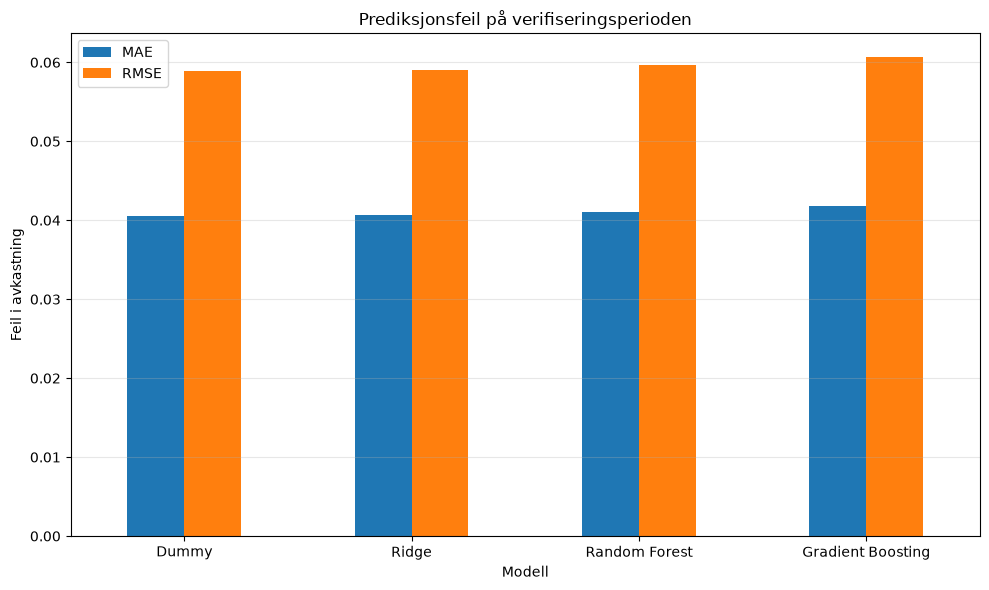

In [10]:
plot_results = results_df.set_index("Model")[["MAE", "RMSE"]]

ax = plot_results.plot(
    kind="bar",
    figsize=(10, 6),
    rot=0
)

ax.set_title("Prediksjonsfeil på verifiseringsperioden")
ax.set_ylabel("Feil i avkastning")
ax.set_xlabel("Modell")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Hjelper sektorinformasjonen?

Den beste algoritmen fra forrige steg kjøres på nytt: først med bare aksjens egne egenskaper, deretter med de samme egenskapene pluss sektor- og markedssignal.

In [11]:
learned_results = (
    results_df[results_df["Model"] != "Dummy"]
    .sort_values("MAE")
)

feature_test_model_name = learned_results.iloc[0]["Model"]
feature_test_model_template = models[feature_test_model_name]

feature_experiments = {
    "Uten sektorinformasjon": baseline_features,
    "Med sektorinformasjon": all_features
}

sector_results = []

for experiment_name, features in feature_experiments.items():
    experiment_model = clone(feature_test_model_template)

    experiment_model.fit(
        model_data.loc[train_mask, features],
        y_train
    )

    predictions = experiment_model.predict(
        model_data.loc[verify_mask, features]
    )

    sector_results.append({
        "Eksperiment": experiment_name,
        "MAE": mean_absolute_error(
            y_verify, predictions
        ),
        "RMSE": np.sqrt(mean_squared_error(
            y_verify, predictions
        )),
        "R2": r2_score(
            y_verify, predictions
        ),
        "Direction_Accuracy": np.mean(
            np.sign(predictions)
            == np.sign(y_verify.to_numpy())
        )
    })

sector_results_df = pd.DataFrame(sector_results)

print("Algoritme brukt i sektortesten:", feature_test_model_name)
sector_results_df

Algoritme brukt i sektortesten: Ridge


,Eksperiment,MAE,RMSE,R2,Direction_Accuracy
0,Uten sektorinformasjon,0.040643,0.058991,-0.004048,0.520116
1,Med sektorinformasjon,0.040651,0.059005,-0.004500,0.518095


## 9. Endelig test

Vi velger kombinasjonen som fikk lavest MAE på verifiseringsperioden. Deretter trener vi den på både trenings- og verifiseringsdata og evaluerer én gang på testperioden.

In [12]:
best_learned_experiment = (
    sector_results_df
    .sort_values("MAE")
    .iloc[0]["Eksperiment"]
)

best_learned_mae = sector_results_df["MAE"].min()
dummy_validation_mae = results_df.loc[
    results_df["Model"] == "Dummy",
    "MAE"
].iloc[0]

if dummy_validation_mae <= best_learned_mae:
    final_model_name = "Dummy"
    final_feature_choice = "Ingen – Dummy bruker ikke egenskapene"
    final_features = all_features
    final_model_template = models["Dummy"]
else:
    final_model_name = feature_test_model_name
    final_feature_choice = best_learned_experiment
    final_features = feature_experiments[best_learned_experiment]
    final_model_template = feature_test_model_template

train_verify_mask = train_mask | verify_mask

final_model = clone(final_model_template)
final_model.fit(
    model_data.loc[train_verify_mask, final_features],
    model_data.loc[train_verify_mask, "Target_Return"]
)

test_predictions = final_model.predict(
    model_data.loc[test_mask, final_features]
)

test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)
test_direction_accuracy = np.mean(
    np.sign(test_predictions)
    == np.sign(y_test.to_numpy())
)

print("Valgt algoritme:", final_model_name)
print("Valgte egenskaper:", final_feature_choice)
print(f"Test MAE: {test_mae:.4f} ({test_mae:.2%})")
print(f"Test RMSE: {test_rmse:.4f} ({test_rmse:.2%})")
print(f"Test R²: {test_r2:.4f}")
print(f"Retningsnøyaktighet: {test_direction_accuracy:.2%}")

Valgt algoritme: Dummy
Valgte egenskaper: Ingen – Dummy bruker ikke egenskapene
Test MAE: 0.0357 (3.57%)
Test RMSE: 0.0546 (5.46%)
Test R²: -0.0000
Retningsnøyaktighet: 53.95%


## 10. Se faktiske og predikerte verdier

Punkter nær den diagonale linjen er gode prediksjoner. Stor spredning betyr at den nøyaktige avkastningen er vanskelig å forutsi.

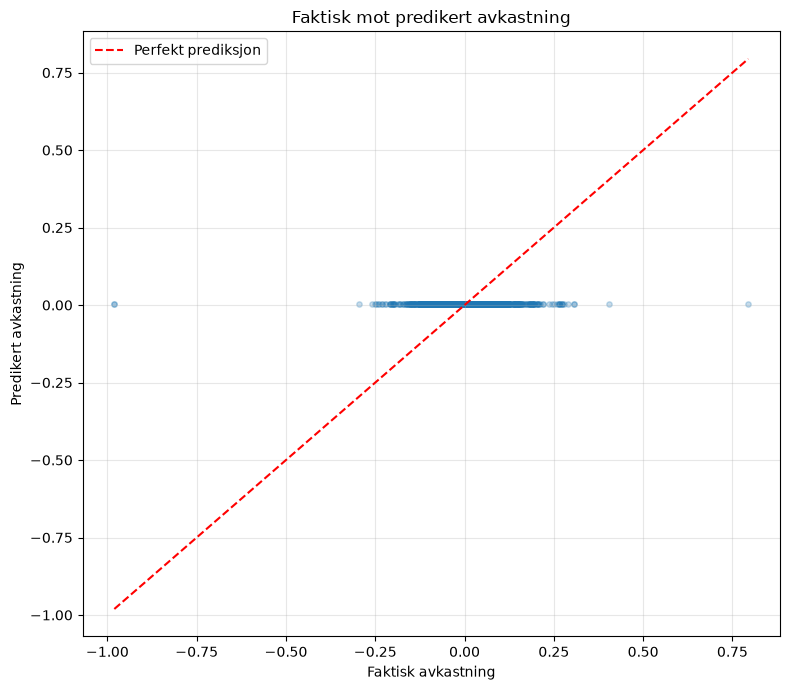

In [13]:
sample_size = min(5000, len(y_test))
sample_indices = np.linspace(
    0,
    len(y_test) - 1,
    sample_size,
    dtype=int
)

actual_sample = y_test.to_numpy()[sample_indices]
predicted_sample = test_predictions[sample_indices]

lower_limit = min(actual_sample.min(), predicted_sample.min())
upper_limit = max(actual_sample.max(), predicted_sample.max())

fig, ax = plt.subplots(figsize=(8, 7))

ax.scatter(
    actual_sample,
    predicted_sample,
    alpha=0.25,
    s=15
)

ax.plot(
    [lower_limit, upper_limit],
    [lower_limit, upper_limit],
    color="red",
    linestyle="--",
    label="Perfekt prediksjon"
)

ax.set_title("Faktisk mot predikert avkastning")
ax.set_xlabel("Faktisk avkastning")
ax.set_ylabel("Predikert avkastning")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Lagre resultatene

CSV-filen gjør det mulig å undersøke prediksjonene senere uten å trene modellen på nytt.

In [14]:
prediction_results = model_data.loc[
    test_mask,
    ["Date", "Ticker", "Industry_Tag", "Target_Return"]
].copy()

prediction_results["Predicted_Return"] = test_predictions
prediction_results["Correct_Direction"] = (
    np.sign(prediction_results["Predicted_Return"])
    == np.sign(prediction_results["Target_Return"])
)

output_file = (
    PROCESSED_DIR
    / f"return_predictions_{FORECAST_DAYS}d.csv"
)

prediction_results.to_csv(output_file, index=False)

print("Lagret:", output_file)
prediction_results.head()

Lagret: c:\Users\47908\Documents\GitHub\stock-direction-prediction\data\processed\return_predictions_5d.csv


,Date,Ticker,Industry_Tag,Target_Return,Predicted_Return,Correct_Direction
107868,2023-11-20 00:00:00+00:00,AAPL,technology,-0.005484,0.003654,False
107869,2023-11-20 00:00:00+00:00,ABNB,hospitality,-0.016500,0.003654,False
107870,2023-11-20 00:00:00+00:00,ADBE,technology,0.017333,0.003654,True
107871,2023-11-20 00:00:00+00:00,ADDYY,apparel,0.028305,0.003654,True
107872,2023-11-20 00:00:00+00:00,AEO,apparel,-0.089620,0.003654,False


## Hvordan resultatet skal tolkes

1. Den beste modellen må ha lavere MAE enn Dummy-modellen. Ellers har den ikke slått en enkel gjennomsnittsgjetning.
2. Positiv R² er ønskelig. Negativ R² betyr at modellen gjør det dårligere enn gjennomsnittsgjetningen.
3. Sammenlign testen med og uten sektorinformasjon. Sektordata hjelper bare dersom feilen faktisk blir lavere på verifiseringsperioden.
4. Testresultatet er den endelige vurderingen. Ikke endre modellen gjentatte ganger basert på testsettet.
5. Store økonomiske kriser beholdes. De er virkelige markedsperioder og viser om modellen tåler endrede markedsforhold.